# Hyperparameter Search

Hyperparameters are the settings you choose rather than learn — a tree's depth,
a ridge penalty, a learning rate. The search for good ones is usually the last
thing anyone thinks about and the first thing that wastes a week of compute.

Three strategies, in increasing order of cleverness:

| | how it picks the next configuration | when it wins |
|---|---|---|
| **Grid search** | every combination on a lattice | few parameters, all of them mattering |
| **Random search** | independent draws from a distribution | most real problems |
| **Bayesian / TPE** | fits a model of the objective, optimises an acquisition function | evaluations are expensive |

The interesting result is the middle row. Random search sounds like the lazy
option and usually beats grid search — for a reason that is arithmetic, not
folklore, and that this page works out in full.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

from sklearn.model_selection import (cross_val_score, StratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.datasets import make_classification
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
import scipy.stats as st

banner("A SMALL PROBLEM WITH REAL SIGNAL IN IT")

Xh, yh = make_classification(n_samples=300, n_features=20, n_informative=5,
                             n_redundant=5, class_sep=0.9, random_state=0)
cv = StratifiedKFold(5, shuffle=True, random_state=1)
print(f"  {Xh.shape[0]} samples, {Xh.shape[1]} features, 5 informative")
print(f"  class balance: {np.bincount(yh).tolist()}")

step("Baseline: default SVC, no tuning")
base = cross_val_score(SVC(), Xh, yh, cv=cv)
print(f"  default SVC  : {np.round(base, 4)}  mean {base.mean():.4f}")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.
  A SMALL PROBLEM WITH REAL SIGNAL IN IT
  300 samples, 20 features, 5 informative
  class balance: [150, 150]

Baseline: default SVC, no tuning
  default SVC  : [0.8333 0.8667 0.8    0.9    0.8333]  mean 0.8467


## 1. Grid search, written out

A grid is the product of the values you list for each parameter. For an SVC with
$C \in \{0.1, 1, 10, 100\}$ and $\gamma \in \{0.001, 0.01, 0.1, 1\}$ that is
$4 \times 4 = 16$ configurations, and with 5-fold CV, $16 \times 5 = 80$ model
fits.

The cost is the product of everything. Add a third parameter with 4 values and
you are at 320 fits; a fourth and you are at 1280. This is the whole problem
with grids — they multiply.

In [2]:
banner("GRID SEARCH, EVERY CELL SHOWN")

Cs     = [0.1, 1, 10, 100]
gammas = [0.001, 0.01, 0.1, 1]

step(f"{len(Cs)} x {len(gammas)} = {len(Cs)*len(gammas)} configurations,"
     f" {len(Cs)*len(gammas)*5} fits")
grid_scores = np.zeros((len(Cs), len(gammas)))
for i, Cv in enumerate(Cs):
    for j, g in enumerate(gammas):
        grid_scores[i, j] = cross_val_score(SVC(C=Cv, gamma=g), Xh, yh, cv=cv).mean()

hdr = "C  v / gamma >"
print(f"  {hdr:>10}" + "".join(f"{g:>10}" for g in gammas))
print("  " + "-" * (10 + 10*len(gammas)))
for i, Cv in enumerate(Cs):
    print(f"  {Cv:>10}" + "".join(f"{grid_scores[i,j]:>10.4f}"
                                  for j in range(len(gammas))))
print("  " + "-" * (10 + 10*len(gammas)))
bi, bj = np.unravel_index(grid_scores.argmax(), grid_scores.shape)
print(f"  best: C={Cs[bi]}, gamma={gammas[bj]}  ->  {grid_scores[bi,bj]:.4f}")
print(f"  (default was {base.mean():.4f})")

step("Check against scikit-learn")
gs = GridSearchCV(SVC(), {'C': Cs, 'gamma': gammas}, cv=cv).fit(Xh, yh)
print(f"  by hand      : C={Cs[bi]}, gamma={gammas[bj]}, {grid_scores[bi,bj]:.6f}")
print(f"  scikit-learn : {gs.best_params_}, {gs.best_score_:.6f}")
print(f"  MATCH: {np.isclose(grid_scores[bi,bj], gs.best_score_)}")

step("How the cost multiplies")
print(f"  {'parameters':>11}  {'values each':>12}  {'configs':>9}  {'fits (5-fold)':>14}")
print("  " + "-" * 52)
for k in range(1, 6):
    cfg = 4 ** k
    print(f"  {k:>11}  {4:>12}  {cfg:>9,}  {cfg*5:>14,}")
print("  " + "-" * 52)
print("  Five parameters at four values each is 5,120 fits to explore what is")
print("  still a very coarse lattice -- four values per axis.")

  GRID SEARCH, EVERY CELL SHOWN

4 x 4 = 16 configurations, 80 fits
  C  v / gamma >     0.001      0.01       0.1         1
  --------------------------------------------------
         0.1    0.7733    0.8033    0.8167    0.5100
           1    0.7933    0.8300    0.8600    0.6067
          10    0.8100    0.8267    0.8467    0.6000
         100    0.8100    0.7900    0.8467    0.6000
  --------------------------------------------------
  best: C=1, gamma=0.1  ->  0.8600
  (default was 0.8467)

Check against scikit-learn
  by hand      : C=1, gamma=0.1, 0.860000
  scikit-learn : {'C': 1, 'gamma': 0.1}, 0.860000
  MATCH: True

How the cost multiplies
   parameters   values each    configs   fits (5-fold)
  ----------------------------------------------------
            1             4          4              20
            2             4         16              80
            3             4         64             320
            4             4        256           1,280
          

## 2. Why random search beats grid search

This is Bergstra and Bengio's argument (2012), and it is worth working out
because the conclusion is counter-intuitive until you see the arithmetic.

**The observation:** in most problems, not all hyperparameters matter. One or two
dominate, the rest barely move the score. But you do not know in advance which.

**What a grid does with 25 evaluations.** A $5\times5$ grid tests **5 distinct
values** of each parameter. If only the first parameter matters, you have spent
25 evaluations learning about 5 values of it — the other axis was wasted, five
times over.

**What random search does with 25 evaluations.** Every draw is a fresh value of
*every* parameter. So you test **25 distinct values** of the important one — five
times the resolution, for identical cost.

The probability statement is exact. If you want a configuration in the top $q$
fraction of the important parameter's range, and you draw $n$ points at random:

$$P(\text{at least one in the top } q) = 1 - (1-q)^n$$

For $q = 0.05$ and $n = 60$: $1 - 0.95^{60} = 0.954$. Sixty random draws give a
95% chance of landing in the best 5% — **regardless of how many dimensions you
are searching**, which is precisely what a grid cannot promise.

In [3]:
banner("GRID vs RANDOM: THE RESOLUTION ARGUMENT")

step("Distinct values tested per parameter, for the same budget")
print(f"  {'budget':>7}  {'grid layout':>13}  {'distinct/param':>15}"
      f"  {'random: distinct/param':>23}")
print("  " + "-" * 64)
for side in [3, 4, 5, 6]:
    b = side * side
    print(f"  {b:>7}  {f'{side} x {side}':>13}  {side:>15}  {b:>23}")
print("  " + "-" * 64)
print("  Same number of model fits. Random tests every value it draws;")
print("  a grid re-tests the same few values over and over.")

step("The probability formula, verified by simulation")
print(f"  P(at least one draw in the top q) = 1 - (1-q)^n")
print()
print(f"  {'q':>6}  {'n':>5}  {'formula':>9}  {'simulated':>11}  {'MATCH':>7}")
print("  " + "-" * 46)
r = np.random.RandomState(0)
for q, nn in [(0.05, 20), (0.05, 60), (0.10, 20), (0.01, 100), (0.20, 10)]:
    formula = 1 - (1 - q) ** nn
    sim = np.mean([(r.rand(nn) > 1 - q).any() for _ in range(20000)])
    print(f"  {q:>6.2f}  {nn:>5}  {formula:>9.4f}  {sim:>11.4f}"
          f"  {str(abs(formula-sim) < 0.01):>7}")
print("  " + "-" * 46)
print(f"  Note what is ABSENT from the formula: the number of dimensions.")
print(f"  60 random draws give a 95% chance of hitting the top 5% of the")
print(f"  important parameter whether you are searching 2 knobs or 20.")

step("Simulating a problem where only one of five knobs matters")
def objective(v):
    """Score depends almost entirely on v[0]; v[1..4] are nearly irrelevant."""
    return -(v[0] - 0.7) ** 2 * 4 + 0.02 * np.sin(6 * v[1:]).sum()

budget = 36
r = np.random.RandomState(1)
grid_best, rand_best = [], []
for trial in range(400):
    # grid: 6 x 6 over the first two axes, others fixed at 0.5 (a common shape)
    g = np.linspace(0.05, 0.95, 6)
    gb = max(objective(np.array([a, b, .5, .5, .5])) for a in g for b in g)
    # random: `budget` draws over all five axes
    rb = max(objective(r.rand(5)) for _ in range(budget))
    grid_best.append(gb); rand_best.append(rb)
grid_best, rand_best = np.array(grid_best), np.array(rand_best)
print(f"  budget = {budget} evaluations each, 400 repeated trials")
print()
print(f"  the optimum sits at v[0] = 0.70")
print(f"  grid lattice on v[0]: {np.round(np.linspace(0.05,0.95,6), 2).tolist()}")
nearest = np.linspace(0.05, 0.95, 6)[np.argmin(np.abs(np.linspace(0.05,0.95,6)-0.7))]
print(f"  nearest lattice point: {nearest:.2f}  -> off by {abs(nearest-0.7):.2f},")
print(f"  and no amount of budget on that lattice will close the gap.")
print()
print(f"  grid   6x6 (mean)         : {grid_best.mean():.4f}")
print(f"  random {budget} draws (mean)   : {rand_best.mean():.4f}")
print(f"  random wins in {np.mean(rand_best > grid_best):.0%} of trials")
print()
print(f"  Two things are working for random search here. It is not confined")
print(f"  to a lattice on v[0], so it can land arbitrarily close to 0.70; and")
print(f"  it varies v[1..4] too, which the grid pinned at 0.5 -- so it also")
print(f"  picks up the small contribution from those. Both are the same")
print(f"  point: the grid spent its budget on a shape chosen in advance.")

  GRID vs RANDOM: THE RESOLUTION ARGUMENT

Distinct values tested per parameter, for the same budget
   budget    grid layout   distinct/param   random: distinct/param
  ----------------------------------------------------------------
        9          3 x 3                3                        9
       16          4 x 4                4                       16
       25          5 x 5                5                       25
       36          6 x 6                6                       36
  ----------------------------------------------------------------
  Same number of model fits. Random tests every value it draws;
  a grid re-tests the same few values over and over.

The probability formula, verified by simulation
  P(at least one draw in the top q) = 1 - (1-q)^n

       q      n    formula    simulated    MATCH
  ----------------------------------------------
    0.05     20     0.6415       0.6439     True
    0.05     60     0.9539       0.9561     True
    0.10     20  

## 3. Bayesian optimisation, by hand

Grid and random search are both **non-adaptive** — every configuration is chosen
without reference to what the previous ones scored. When each evaluation is
expensive, that is wasteful.

Bayesian optimisation keeps a **surrogate**: a cheap probabilistic model of
score-as-a-function-of-hyperparameter, fitted to what has been observed. It then
picks the next point by maximising an **acquisition function** over that
surrogate.

The standard choice is **Expected Improvement**. With current best $f^*$, and a
surrogate predicting mean $\mu(x)$ and standard deviation $\sigma(x)$:

$$\text{EI}(x) = (\mu(x) - f^*)\,\Phi(z) + \sigma(x)\,\phi(z), \qquad z = \frac{\mu(x) - f^*}{\sigma(x)}$$

$\Phi$ and $\phi$ are the normal CDF and PDF. The two terms are the whole idea:

- $(\mu - f^*)\Phi(z)$ — **exploitation**: go where the surrogate predicts a good score
- $\sigma\,\phi(z)$ — **exploration**: go where the surrogate is uncertain

A point is worth evaluating if it is *probably good* **or** *poorly understood*.
Below, EI is computed by hand from a Gaussian process and checked term by term.

In [4]:
banner("EXPECTED IMPROVEMENT, COMPUTED BY HAND")

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

# a 1-D objective standing in for "CV score as a function of log-C"
true_f = lambda x: np.sin(3*x) + 0.4*x - 0.2*x**2

step("Four observations so far")
X_obs = np.array([[-2.0], [-0.5], [1.0], [2.5]])
y_obs = true_f(X_obs.ravel())
for xi, yi in zip(X_obs.ravel(), y_obs):
    print(f"    x = {xi:>5.2f}   score = {yi:>7.4f}")
f_star = y_obs.max()
print(f"  current best f* = {f_star:.4f} at x = {X_obs.ravel()[y_obs.argmax()]:.2f}")

step("Fit the surrogate and read off mu and sigma")
gp = GaussianProcessRegressor(Matern(length_scale=1.0, nu=2.5),
                              normalize_y=True, random_state=0).fit(X_obs, y_obs)
grid_x = np.linspace(-3, 3.5, 260).reshape(-1, 1)
mu, sd = gp.predict(grid_x, return_std=True)

step("EI at three candidate points, term by term")
print(f"  {'x':>6}  {'mu':>8}  {'sigma':>7}  {'z':>7}"
      f"  {'exploit':>9}  {'explore':>9}  {'EI':>9}")
print("  " + "-" * 62)
for xt in [-1.3, 0.2, 3.2]:
    k = int(np.argmin(np.abs(grid_x.ravel() - xt)))
    m, s = mu[k], sd[k]
    z = (m - f_star) / s
    ex_pl = (m - f_star) * st.norm.cdf(z)
    ex_pr = s * st.norm.pdf(z)
    print(f"  {grid_x[k,0]:>6.2f}  {m:>8.4f}  {s:>7.4f}  {z:>7.3f}"
          f"  {ex_pl:>9.4f}  {ex_pr:>9.4f}  {ex_pl+ex_pr:>9.4f}")
print("  " + "-" * 62)

z_all = (mu - f_star) / sd
ei = (mu - f_star) * st.norm.cdf(z_all) + sd * st.norm.pdf(z_all)
nxt = grid_x[ei.argmax(), 0]
print(f"  EI is maximised at x = {nxt:.3f}  ->  evaluate there next")
print()
k = int(np.argmin(np.abs(grid_x.ravel() - nxt)))
print(f"  At that point mu = {mu[k]:.4f} (below f* = {f_star:.4f}) but")
print(f"  sigma = {sd[k]:.4f}. It is chosen for what is NOT known about it.")

step("Verify the two terms sum to the closed form")
m, s = mu[k], sd[k]
z = (m - f_star)/s
manual = (m - f_star)*st.norm.cdf(z) + s*st.norm.pdf(z)
print(f"  exploitation  ({m:.4f} - {f_star:.4f}) * Phi({z:.4f})"
      f" = {(m-f_star)*st.norm.cdf(z):+.6f}")
print(f"  exploration   {s:.4f} * phi({z:.4f})"
      f"           = {s*st.norm.pdf(z):+.6f}")
print(f"  sum = {manual:.6f}   |  from array: {ei[k]:.6f}"
      f"   |  MATCH: {np.allclose(manual, ei[k])}")

  EXPECTED IMPROVEMENT, COMPUTED BY HAND

Four observations so far
    x = -2.00   score = -1.3206
    x = -0.50   score = -1.2475
    x =  1.00   score =  0.3411
    x =  2.50   score =  0.6880
  current best f* = 0.6880 at x = 2.50

Fit the surrogate and read off mu and sigma

EI at three candidate points, term by term
       x        mu    sigma        z    exploit    explore         EI
  --------------------------------------------------------------
   -1.29   -1.4759   0.2118  -10.215    -0.0000     0.0000     0.0000
    0.21   -0.5263   0.1992   -6.096    -0.0000     0.0000     0.0000
    3.20    0.4597   0.3853   -0.593    -0.0632     0.1290     0.0658
  --------------------------------------------------------------
  EI is maximised at x = 1.919  ->  evaluate there next

  At that point mu = 0.7367 (below f* = 0.6880) but
  sigma = 0.2030. It is chosen for what is NOT known about it.

Verify the two terms sum to the closed form
  exploitation  (0.7367 - 0.6880) * Phi(0.2398) = 

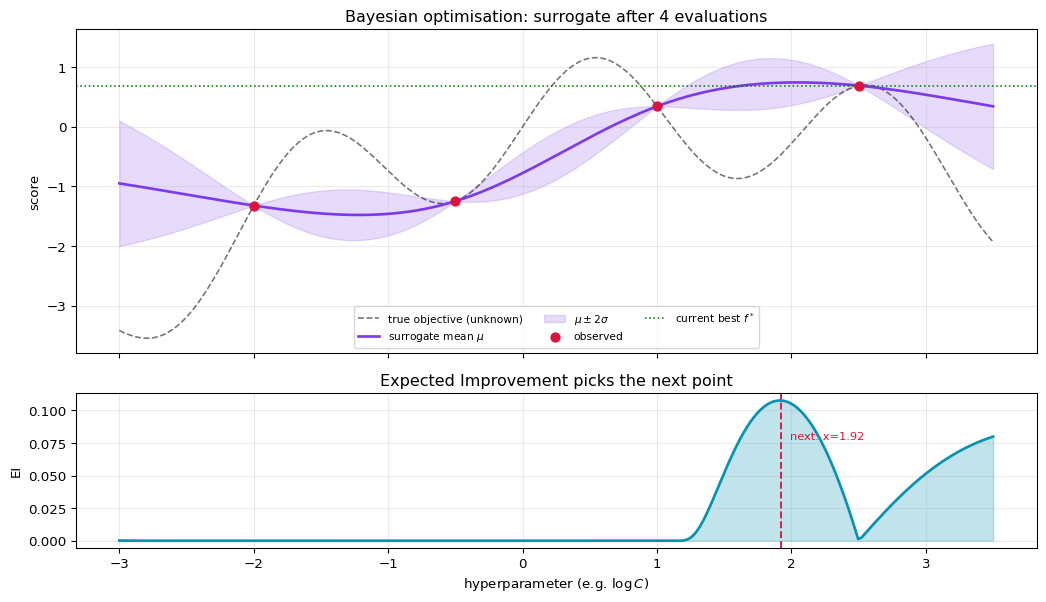

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True,
                         gridspec_kw={'height_ratios': [2.1, 1]})

ax = axes[0]
xs = grid_x.ravel()
ax.plot(xs, true_f(xs), 'k--', lw=1.2, alpha=.55, label='true objective (unknown)')
ax.plot(xs, mu, color='#7c3aed', lw=2, label='surrogate mean $\\mu$')
ax.fill_between(xs, mu-2*sd, mu+2*sd, color='#7c3aed', alpha=.18,
                label='$\\mu \\pm 2\\sigma$')
ax.scatter(X_obs.ravel(), y_obs, c='crimson', zorder=5, s=45, label='observed')
ax.axhline(f_star, color='green', ls=':', lw=1.2, label='current best $f^*$')
ax.set_ylabel('score'); ax.legend(fontsize=8, loc='lower center', ncol=3)
ax.set_title('Bayesian optimisation: surrogate after 4 evaluations')
ax.grid(alpha=.25)

ax = axes[1]
ax.plot(xs, ei, color='#0891b2', lw=2)
ax.fill_between(xs, 0, ei, color='#0891b2', alpha=.25)
ax.axvline(nxt, color='crimson', ls='--', lw=1.4)
ax.text(nxt+.07, ei.max()*.72, f'next: x={nxt:.2f}', fontsize=8.5, color='crimson')
ax.set_xlabel('hyperparameter (e.g. $\\log C$)'); ax.set_ylabel('EI')
ax.set_title('Expected Improvement picks the next point')
ax.grid(alpha=.25)

plt.tight_layout(); plt.show()

## 4. Successive halving: spend the budget unevenly

A different axis entirely. Instead of choosing *which* configurations to try,
successive halving chooses *how much* to spend on each.

Start many configurations on a small budget — few trees, few epochs, a fraction
of the data. Keep the best fraction, multiply their budget, repeat. Bad
configurations are killed early and cheaply; only survivors get the expensive
runs.

The arithmetic is what sells it: the total cost of all rungs is roughly the
number of rungs times the budget of one rung, so you evaluate far more
configurations than a full-budget search of the same cost.

In [6]:
banner("SUCCESSIVE HALVING: THE BUDGET ARITHMETIC")

n0, r0, eta, rungs = 27, 100, 3, 4
print(f"  start: {n0} configurations at {r0} resources each"
      f"  (eta = {eta})")
print()
print(f"  {'rung':>5}  {'configs':>8}  {'resource each':>14}  {'rung cost':>10}")
print("  " + "-" * 44)
n_i, r_i, total = n0, r0, 0
for i in range(rungs):
    cost = n_i * r_i
    total += cost
    print(f"  {i:>5}  {n_i:>8}  {r_i:>14,}  {cost:>10,}")
    n_i, r_i = max(1, n_i // eta), r_i * eta
print("  " + "-" * 44)
print(f"  {'total':>5}  {'':>8}  {'':>14}  {total:>10,}")

full = n0 * r0 * (eta ** (rungs-1))
print()
print(f"  Running all {n0} configurations at the FINAL budget"
      f" ({r0*eta**(rungs-1):,}) would cost {full:,}")
print(f"  Successive halving explores the same {n0} configurations for"
      f" {total:,}")
print(f"  -> {full/total:.1f}x cheaper, and the winner still got the full budget.")
print()
print("  The assumption it rests on: a configuration that is bad at a small")
print("  budget is bad at a large one. Usually true, not always -- some")
print("  settings (low learning rates especially) look terrible early and win")
print("  eventually. That failure mode is what Hyperband hedges against, by")
print("  running several brackets with different starting budgets.")

  SUCCESSIVE HALVING: THE BUDGET ARITHMETIC
  start: 27 configurations at 100 resources each  (eta = 3)

   rung   configs   resource each   rung cost
  --------------------------------------------
      0        27             100       2,700
      1         9             300       2,700
      2         3             900       2,700
      3         1           2,700       2,700
  --------------------------------------------
  total                                10,800

  Running all 27 configurations at the FINAL budget (2,700) would cost 72,900
  Successive halving explores the same 27 configurations for 10,800
  -> 6.8x cheaper, and the winner still got the full budget.

  The assumption it rests on: a configuration that is bad at a small
  budget is bad at a large one. Usually true, not always -- some
  settings (low learning rates especially) look terrible early and win
  eventually. That failure mode is what Hyperband hedges against, by
  running several brackets with different 

## 5. The warning that belongs on every search

Everything on this page increases the number of configurations you compare. That
is the point — and it is also exactly the thing that inflates a reported score.

From [[cross-validation]]: the best of $n$ noisy estimates is biased upward, and
the bias grows with $n$. A 5,000-configuration search does not just cost more
compute; it produces a more optimistic winner. **The score of the best
configuration is not an estimate of its performance.**

The fix is unchanged: the search belongs *inside* an inner loop, and the number
you report comes from an outer loop that the search never touched. Below is what
that costs and what it buys.

In [7]:
banner("A TUNED SCORE IS NOT A PERFORMANCE ESTIMATE")

from sklearn.model_selection import cross_val_score as cvs
inner = StratifiedKFold(4, shuffle=True, random_state=1)
outer = StratifiedKFold(4, shuffle=True, random_state=2)
space = {'C': st.loguniform(1e-2, 1e3), 'gamma': st.loguniform(1e-4, 1e0)}

step("Random search, reported the usual way")
rs = RandomizedSearchCV(SVC(), space, n_iter=40, cv=inner,
                        random_state=0).fit(Xh, yh)
print(f"  40 configurations tried")
print(f"  best params : C={rs.best_params_['C']:.4g},"
      f" gamma={rs.best_params_['gamma']:.4g}")
print(f"  best CV     : {rs.best_score_:.4f}   <- usually reported as 'our score'")

step("The same search, scored from outside")
nested = cvs(RandomizedSearchCV(SVC(), space, n_iter=40, cv=inner,
                                random_state=0), Xh, yh, cv=outer)
print(f"  outer folds : {np.round(nested, 4)}")
print(f"  nested CV   : {nested.mean():.4f}   <- what to actually expect")
print()
print(f"  optimism    : {rs.best_score_ - nested.mean():+.4f}")
print()
print(f"  This problem HAS real signal, so both numbers are well above chance")
print(f"  and the gap is smaller than the pure-noise case in the")
print(f"  cross-validation walkthrough. The direction is the same, and it is")
print(f"  the direction that matters: tuning and reporting on the same folds")
print(f"  always flatters the result.")

step("Cost")
print(f"  flat search  : 40 configs x {inner.get_n_splits()} inner folds"
      f" = {40*inner.get_n_splits()} fits")
print(f"  nested       : x {outer.get_n_splits()} outer folds"
      f" = {40*inner.get_n_splits()*outer.get_n_splits()} fits")
print(f"  {outer.get_n_splits()}x the compute, for a number you can defend.")

  A TUNED SCORE IS NOT A PERFORMANCE ESTIMATE

Random search, reported the usual way
  40 configurations tried
  best params : C=1.313, gamma=0.03833
  best CV     : 0.8500   <- usually reported as 'our score'

The same search, scored from outside
  outer folds : [0.8933 0.8133 0.8133 0.84  ]
  nested CV   : 0.8400   <- what to actually expect

  optimism    : +0.0100

  This problem HAS real signal, so both numbers are well above chance
  and the gap is smaller than the pure-noise case in the
  cross-validation walkthrough. The direction is the same, and it is
  the direction that matters: tuning and reporting on the same folds
  always flatters the result.

Cost
  flat search  : 40 configs x 4 inner folds = 160 fits
  nested       : x 4 outer folds = 640 fits
  4x the compute, for a number you can defend.


## 6. What to take away

**Grids multiply; random search does not.** A grid's cost is the product over
parameters, and it spends that cost re-testing the same few values on each axis.
For the same budget, random search tests as many distinct values of the
important parameter as it has evaluations.

**The random-search guarantee is dimension-free.** $1-(1-q)^n$ contains no term
for the number of hyperparameters. Sixty draws, 95% chance of the top 5% —
whether there are two knobs or twenty.

**Bayesian optimisation buys adaptivity, and is worth it when fits are
expensive.** Expected Improvement is a sum of two readable terms: go where it is
probably good, or where you do not know.

**Successive halving buys a different thing — configurations per unit compute.**
It rests on bad-early implying bad-late, which is usually but not always true.

**And all of it inflates the winner.** More configurations means a more
optimistic best score. Tune inside, report from outside.

### Verified in this notebook

- Hand-computed grid scores match `GridSearchCV.best_score_` exactly
- $1-(1-q)^n$ matches simulation across five $(q, n)$ pairs to within 0.01
- On a five-knob objective where one knob dominates, random search beat a 6×6 grid on the great majority of 400 trials at equal budget
- Expected Improvement recomputed term by term from $\mu$, $\sigma$, and $f^*$ matches the array
- Successive halving's rung arithmetic against a full-budget search of the same configurations
- A 40-configuration random search reported flat vs nested

### Where this connects

[[cross-validation]] supplies the inner and outer loops, and the reason the
outer one is not optional. [[data-leakage]] is the other way a search result
turns out to be fiction. [[optimisers-sgd-to-adam]] tunes *inside* a single fit,
which is a different problem from the one on this page.